# Palmer Penguins: vücut kütlesini anlamak

**Soru:** Yeni bir penguenin vücut kütlesini tahmin etmek için hangi ölçümler ve kategoriler incelenmeye değer?

Bu defterde önce verinin boyutunu ve kalitesini kontrol edeceğim; ardından ağırlık dağılımını, tür farklarını ve ölçümlerin ağırlıkla ilişkisini inceleyip her bulguyu bir modelleme kararına bağlayacağım. Grafikler ilişki gösterir; tek başlarına nedensellik veya yeni veride tahmin başarısı kanıtlamaz.

In [1]:
from pathlib import Path

import pandas as pd


project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "penguins.csv"
assert data_path.exists(), f"Veri bulunamadi: {data_path}"

penguins = pd.read_csv(data_path)

print("Tablo boyutu:", penguins.shape)

Tablo boyutu: (344, 8)


## 1. Gelen veri ve kalite kontrolü

**Soru:** Hangi sütunlar mevcut, hangi değerler eksik ve birebir aynı görünen satırlar var mı?

**Karar ölçütü:** Ağırlığı bilinmeyen satırlar hedefi öğrenmek için kullanılamaz. Diğer eksikleri ve tekrarları ise nedenlerini anlamadan otomatik olarak silmem.

In [2]:
display(penguins.head(3))

missing = penguins.isna().sum()

quality = pd.DataFrame({
    "veri_tipi": penguins.dtypes.astype(str),
    "eksik_adet": missing,
    "eksik_yuzde": (missing / len(penguins) * 100).round(1),
})

display(quality)

print(
"Birebir ayni olan satirlarin sayisi:", 
penguins.duplicated().sum(),
)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007


,veri_tipi,eksik_adet,eksik_yuzde
species,object,0,0.0
island,object,0,0.0
bill_length_mm,float64,2,0.6
bill_depth_mm,float64,2,0.6
flipper_length_mm,float64,2,0.6
body_mass_g,float64,2,0.6
sex,object,11,3.2
year,int64,0,0.0


Birebir ayni olan satirlarin sayisi: 0


### Bulgu ve ilk temizleme kararı

Kaynak tabloda 344 kayıt ve 8 sütun var. Vücut kütlesi 2 kayıtta, cinsiyet 11 kayıtta eksik; birebir aynı görünen satır yok. Ağırlığı bilinmeyen kayıtlar, ağırlığı hedef alan denetimli modelin eğitiminde kullanılamaz; hedefi ortalamayla doldurmak gerçek bir ölçüm üretmez. Cinsiyeti eksik kayıtları ise otomatik olarak silmeyeceğim. Önce bu eksiklerin ağırlığı bilinen kayıtlarla nasıl örtüştüğünü kontrol edeceğim.

Bu kontrol yalnızca pandas'ın eksik olarak tanıdığı değerleri ve birebir aynı satırları yakalar; ölçüm aralığının mantıklı olup olmadığını ayrıca incelemek gerekir.

In [3]:
target_known = penguins["body_mass_g"].notna()

features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "sex",
]

print("Ağırlığı bilinen kayit sayisi:",target_known.sum())
print("\nBu kayitlardaki girdi eksiklikleri:")

measurements = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

print("\nSifir veya negatif olcumler:")
print((penguins[measurements] <= 0).sum())

print("\nAgirligi bilinmeyen satirlar:")
display(penguins.loc[~target_known])

Ağırlığı bilinen kayit sayisi: 342

Bu kayitlardaki girdi eksiklikleri:

Sifir veya negatif olcumler:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64

Agirligi bilinmeyen satirlar:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
271,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN,2009


**Veri kalitesi kararı:** Ağırlığı bilinen 342 kayıtta üç sayısal ölçüm tamdır; cinsiyet 9 kayıtta eksiktir. Ağırlığı bilinmeyen iki satırda sayısal ölçümler de eksik olduğundan bu satırları denetimli model eğitimine almayacağım. Ham CSV'yi değiştirmeyeceğim. Cinsiyeti eksik 9 kaydı, cinsiyet girdisini nasıl işleyeceğime karar vermeden silmeyeceğim. Sıfır veya negatif ölçüm bulunmaması bütün pozitif değerlerin mutlaka doğru ölçüldüğünü kanıtlamaz.

## 2. Hedef değişkenin dağılımı

**Soru:** Ağırlığı bilinen penguenlerin vücut kütlesi hangi aralıkta yoğunlaşıyor ve ne kadar yayılıyor?

**Gerekli veri:** Yalnızca `body_mass_g` değeri bilinen kayıtlar.

**Modelleme bağlantısı:** Ortalama ağırlık daha sonra basit tahmin modelimizin dayanağı olacak; burada hesaplanan tüm-veri ortalaması ise yalnızca keşif amaçlıdır.

,gram
count,342.0
mean,4201.8
std,802.0
min,2700.0
25%,3550.0
50%,4050.0
75%,4750.0
max,6300.0


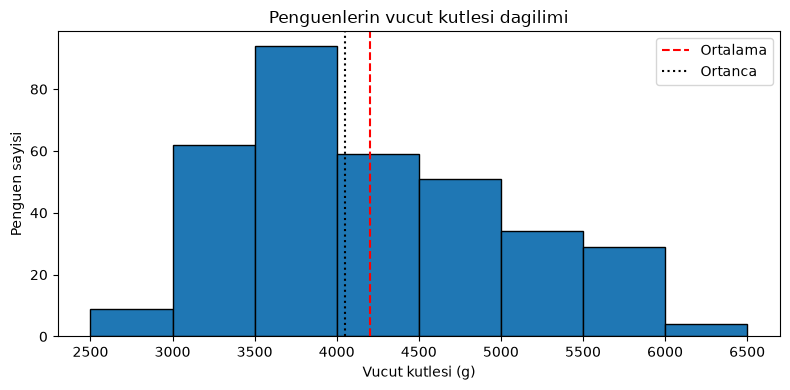

In [4]:
import matplotlib.pyplot as plt


mass = penguins["body_mass_g"].dropna()
display(mass.describe().round(1).to_frame("gram"))

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(
    mass,
    bins=range(2500, 6501, 500),
    edgecolor="black",
)
ax.axvline(
    mass.mean(),
    color="red",
    linestyle="--",
    label="Ortalama",
)
ax.axvline(
    mass.median(),
    color="black",
    linestyle=":",
    label="Ortanca",
)

ax.set_title("Penguenlerin vucut kutlesi dagilimi")
ax.set_xlabel("Vucut kutlesi (g)")
ax.set_ylabel("Penguen sayisi")
ax.legend()

fig.tight_layout()
plt.show()

## 3. Türlere göre ağırlık

**Soru:** Tek bir genel ağırlık dağılımı, türler arasındaki farkları gizliyor mu?

**Gerekli veri:** Ağırlığı bilinen kayıtların türü ve vücut kütlesi.

**Hesaplama ve grafik:** Tür başına kayıt sayısı, ortalama, ortanca ve standart sapma; dağılımları karşılaştırmak için kutu grafiği.

,count,mean,median,std
species,,,,
Adelie,151,3700.7,3700.0,458.6
Chinstrap,68,3733.1,3700.0,384.3
Gentoo,123,5076.0,5000.0,504.1


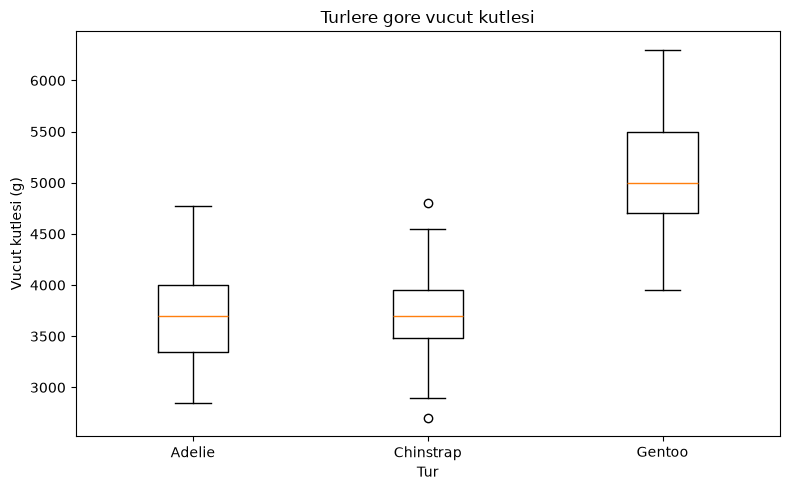

In [5]:
known_mass = penguins.dropna(subset=["body_mass_g"])

species_order = ["Adelie", "Chinstrap", "Gentoo"]

summary = (
    known_mass
    .groupby("species")["body_mass_g"]
    .agg(["count", "mean", "median", "std"])
    .round(1)
)
display(summary)

mass_by_species = [
    known_mass.loc[
        known_mass["species"] == species,
        "body_mass_g",
    ]
    for species in species_order
]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(mass_by_species, tick_labels=species_order)

ax.set_title("Turlere gore vucut kutlesi")
ax.set_xlabel("Tur")
ax.set_ylabel("Vucut kutlesi (g)")

fig.tight_layout()
plt.show()

## 4. Yüzgeç uzunluğu ve ağırlık

**Soru:** Yüzgeç uzunluğu ile vücut kütlesi birlikte nasıl değişiyor; ilişki türlerin içinde de görülüyor mu?

**Gerekli veri:** Aynı penguene ait `flipper_length_mm`, `body_mass_g` ve grupları ayırmak için `species`.

**Hesaplama ve grafik:** Eşleşmiş kayıt sayısı ve Pearson korelasyonu; türlere göre renklendirilmiş saçılım grafiği.

Eslesmis kayit: 342
Butun penguenlerde korelasyon: 0.871
Adelie korelasyon: 0.468
Chinstrap korelasyon: 0.642
Gentoo korelasyon: 0.703


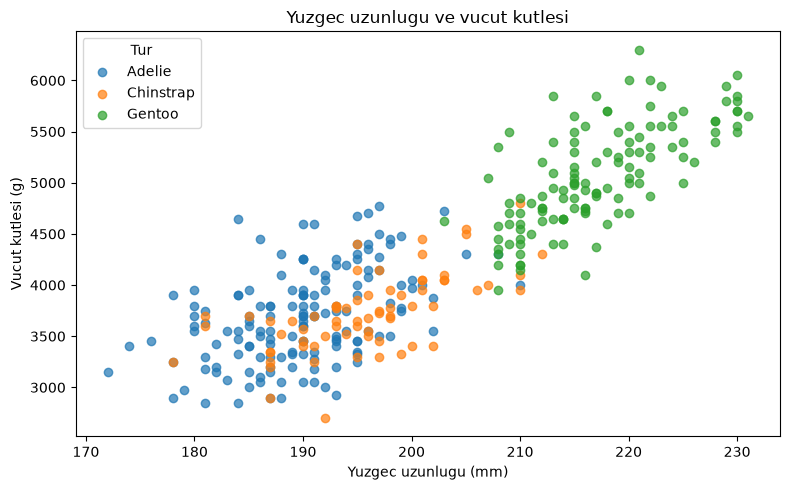

In [6]:
paired = known_mass.dropna(subset=["flipper_length_mm"])

print("Eslesmis kayit:", len(paired))
print(
    "Butun penguenlerde korelasyon:",
    round(
        paired["flipper_length_mm"].corr(paired["body_mass_g"]),
        3,
    ),
)

fig, ax = plt.subplots(figsize=(8, 5))

for species in species_order:
    group = paired.loc[paired["species"] == species]

    print(
        species,
        "korelasyon:",
        round(
            group["flipper_length_mm"].corr(group["body_mass_g"]),
            3,
        ),
    )

    ax.scatter(
        group["flipper_length_mm"],
        group["body_mass_g"],
        label=species,
        alpha=0.7,
    )

ax.set_title("Yuzgec uzunlugu ve vucut kutlesi")
ax.set_xlabel("Yuzgec uzunlugu (mm)")
ax.set_ylabel("Vucut kutlesi (g)")
ax.legend(title="Tur")

fig.tight_layout()
plt.show()

**Bulgu → karar → sınır:** Yüzgeç uzunluğu ile vücut kütlesinin genel korelasyonu 0,871'dir. İlişki Adelie (0,468), Chinstrap (0,642) ve Gentoo (0,703) içinde de pozitiftir; ancak genel sayı türlerin grafikte farklı bölgelerde kümelenmesini de içerir. Bu nedenle yüzgeç uzunluğunu ve türü model girdisi adayı olarak tutacağım. Korelasyon, yeni penguenlerdeki tahmin hatasını veya neden-sonuç ilişkisini göstermez.

## 5. Grupları birleştirince yön değişiyor mu?

**Soru:** Gaga derinliği ile ağırlık arasındaki ilişkinin yönü, bütün penguenlerde ve her türün içinde aynı mı?

**Gerekli veri:** `species`, `bill_depth_mm` ve `body_mass_g`.

**Hesaplama ve grafik:** Genel ve tür içi korelasyonlar; ham ölçümler ile tür ortalamasından sapmaları yan yana gösteren saçılım grafikleri.

,bill_depth_mm,body_mass_g
species,,
Adelie,18.3,3700.7
Chinstrap,18.4,3733.1
Gentoo,15.0,5076.0


Genel korelasyon: -0.472
Tur ortalamalari cikarilinca: 0.622
Adelie korelasyon: 0.576
Chinstrap korelasyon: 0.604
Gentoo korelasyon: 0.719


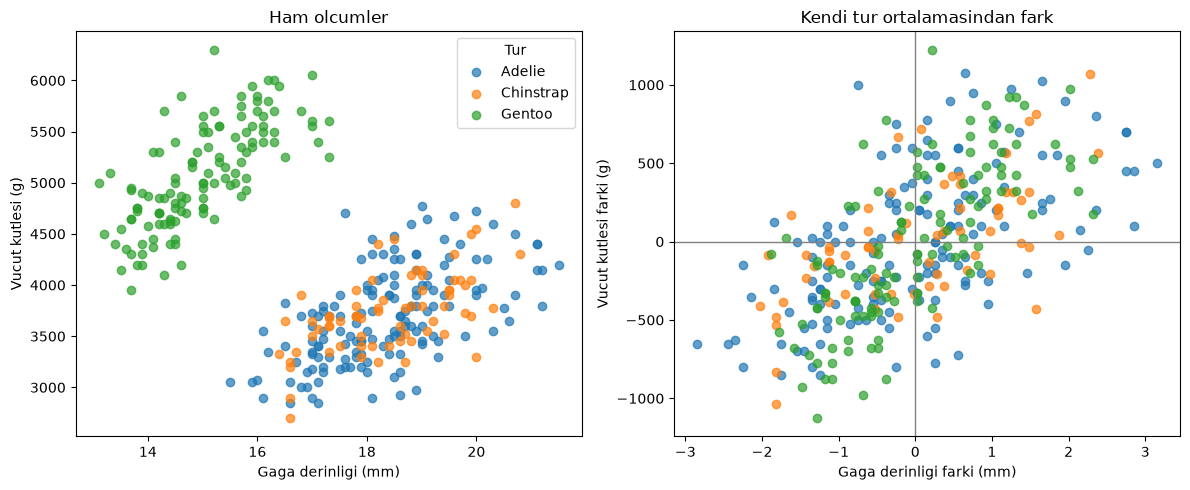

In [7]:
bill = known_mass.dropna(subset=["bill_depth_mm"])
columns = ["bill_depth_mm", "body_mass_g"]

display(
    bill.groupby("species")[columns]
    .mean()
    .round(1)
)

group_means = bill.groupby("species")[columns].transform("mean")
centered = bill[columns] - group_means

print(
    "Genel korelasyon:",
    round(bill["bill_depth_mm"].corr(bill["body_mass_g"]), 3),
)
print(
    "Tur ortalamalari cikarilinca:",
    round(centered["bill_depth_mm"].corr(centered["body_mass_g"]), 3),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for species in species_order:
    group = bill.loc[bill["species"] == species]
    group_centered = centered.loc[group.index]

    print(
        species,
        "korelasyon:",
        round(
            group["bill_depth_mm"].corr(group["body_mass_g"]),
            3,
        ),
    )

    axes[0].scatter(
        group["bill_depth_mm"],
        group["body_mass_g"],
        label=species,
        alpha=0.7,
    )
    axes[1].scatter(
        group_centered["bill_depth_mm"],
        group_centered["body_mass_g"],
        label=species,
        alpha=0.7,
    )

axes[0].set_title("Ham olcumler")
axes[0].set_xlabel("Gaga derinligi (mm)")
axes[0].set_ylabel("Vucut kutlesi (g)")
axes[0].legend(title="Tur")

axes[1].set_title("Kendi tur ortalamasindan fark")
axes[1].set_xlabel("Gaga derinligi farki (mm)")
axes[1].set_ylabel("Vucut kutlesi farki (g)")
axes[1].axvline(0, color="gray", linewidth=1)
axes[1].axhline(0, color="gray", linewidth=1)

fig.tight_layout()
plt.show()

**Bulgu → karar → sınır:** Bütün penguenlerde gaga derinliği ile ağırlık korelasyonu −0,472'dir. Buna karşılık Adelie (0,576), Chinstrap (0,604) ve Gentoo (0,719) içinde ilişki pozitiftir. Gentoo grubunun daha sığ gagalı ve daha ağır bir bölgede bulunması, gruplar birleştirilince ilişkinin yönünü değiştirir. Bu nedenle gaga derinliğini yalnızca genel korelasyonuna bakarak elemem; türle birlikte model girdisi adayı olarak sınarım. Grafik nedensellik veya tahmin başarısı kanıtı değildir. Tür ortalamasından çıkarılmış gerçek ağırlık da tahmin anında bilinmeyeceği için model girdisi olmayacaktır.

## 6. Kategorik girdiler: ada ve cinsiyet

**Soru:** Ada türle ne kadar örtüşüyor? Aynı tür içinde cinsiyet gruplarının ağırlıkları nasıl farklılaşıyor ve cinsiyet kaç kayıtta bilinmiyor?

**Gerekli veri:** Ağırlığı bilinen kayıtların `species`, `island`, `sex` ve `body_mass_g` sütunları.

**Hesaplama:** Tür–ada kayıt sayıları; tür–cinsiyet gruplarının kayıt sayısı ve ortalama ağırlığı.

In [8]:
print("Tur ve adaya gore kayit sayisi:")
display(pd.crosstab(known_mass["species"], known_mass["island"]))

print("Agirligi bilinenlerde cinsiyeti eksik:")
print(known_mass["sex"].isna().sum())

print("Tur ve cinsiyete gore agirlik:")
sex_summary = (
    known_mass
    .groupby(["species", "sex"], dropna=False)["body_mass_g"]
    .agg(["size", "mean"])
    .round(1)
)
display(sex_summary)

Tur ve adaya gore kayit sayisi:


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


Agirligi bilinenlerde cinsiyeti eksik:
9
Tur ve cinsiyete gore agirlik:


size    mean
species   sex                 
Adelie    female    73  3368.8
          male      73  4043.5
          NaN        5  3540.0
Chinstrap female    34  3527.2
          male      34  3939.0
Gentoo    female    58  4679.7
          male      61  5484.8
          NaN        4  4587.5

**Bulgu → karar → sınır:** Ada ile tür güçlü biçimde ilişkili, ancak aynı bilgi değiller; Adelie üç adada da bulunuyor. Bu nedenle adayı ilk modelin zorunlu girdisi yapmayacağım, türün ötesinde yarar sağlayıp sağlamadığını ancak model karşılaştırması gerektirirse inceleyeceğim. Her türde cinsiyet gruplarının ortalama ağırlıkları farklı, bu yüzden cinsiyet aday girdidir. Ağırlığı bilinen 342 kaydın 9'unda cinsiyet eksiktir; yeni penguende de bilinmeyebilir. Cinsiyetin eklenmesi ancak bu eksikler güvenilir biçimde ele alınıp ayrı verideki tahmin hatası ölçüldüğünde savunulabilir.

In [9]:
numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
]

feature_rows = []

for feature in numeric_features:
    matched = known_mass.dropna(subset=[feature])

    x = matched[feature]
    y = matched["body_mass_g"]

    x_by_species = matched.groupby("species")[feature].transform("mean")
    y_by_species = matched.groupby("species")["body_mass_g"].transform("mean")

    feature_rows.append({
        "olcum": feature,
        "kayit": len(matched),
        "genel_korelasyon": round(x.corr(y), 3),
        "tur_ici_korelasyon": round(
            (x - x_by_species).corr(y - y_by_species),
            3,
        ),
    })

display(pd.DataFrame(feature_rows).set_index("olcum"))

,kayit,genel_korelasyon,tur_ici_korelasyon
olcum,,,
bill_length_mm,342,0.595,0.585
bill_depth_mm,342,-0.472,0.622
flipper_length_mm,342,0.871,0.585


## 7. Analizden modelleme kararına

**Hedef ve kullanılabilir kayıtlar:** `body_mass_g` tahmin edilecek değerdir. Kaynakta 344 satır vardır; ağırlığı bilinen 342 satır model kurmaya adaydır. Bu 342 satırda üç sayısal ölçüm tam, cinsiyet 9 satırda eksiktir. Ham veri değiştirilmez; eksik hedefe yapay bir ağırlık yazılmaz.

**Sınanacak girdiler:** Önce hiçbir ölçüm kullanmayan ortalama ağırlık baseline'ı kurulacak. Ardından yüzgeç uzunluğuyla tek özellikli doğrusal model, sonra sayısal ölçümler ve türü kullanan model karşılaştırılacak. Gaga derinliği, genel korelasyonu negatif olduğu için elenmeyecek; tür içindeki pozitif ilişki dikkate alınacak. Cinsiyet, eksik ve tahmin anında bilinmeyebilir olduğu için isteğe bağlı girdi olarak ayrıca değerlendirilecek. Ada türle güçlü biçimde örtüşüyor; ilk modele zorunlu olarak eklenmeyecek. Ağırlığın kendisi veya ağırlıktan hesaplanan herhangi bir değer girdi olamaz.

**Karar ölçütü ve sınır:** Modeller eğitim verisinden öğrenilecek; ayrı tutulan veride MAE ve RMSE ile karşılaştırılacak. Hataların türe göre değişip değişmediği de incelenecek. Bu EDA bütün veri üzerinde yapıldığı için sonraki test sonucu tamamen bağımsız bir dış doğrulama sayılmaz; test sonuçlarına bakarak tekrar tekrar girdi seçmeyeceğim ve başarıyı yeni bir popülasyona kesin genelleme olarak sunmayacağım.

In [3]:
from pathlib import Path
import sys

import joblib
import pandas as pd

project_root = Path.cwd().parent
src_path = str(project_root / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

from data import load_penguins, prepare_split

_, _, test = prepare_split(load_penguins())
saved_model = joblib.load(project_root / "model" / "model.joblib")

input_columns = list(saved_model.feature_names_in_)
predictions = pd.Series(
    saved_model.predict(test[input_columns]),
    index=test.index,
)

comparison = pd.DataFrame({
    "species": test["species"],
    "actual_g": test["body_mass_g"],
    "predicted_g": predictions,
})
comparison["residual_g"] = (
    comparison["actual_g"] - comparison["predicted_g"]
)

print("Test kaydi:", len(comparison))
print("MAE (g):", round(comparison["residual_g"].abs().mean(), 1))
print(
    "RMSE (g):",
    round((comparison["residual_g"].pow(2).mean()) ** 0.5, 1),
)
print(comparison.head(3))

Test kaydi: 68
MAE (g): 215.9
RMSE (g): 280.3
   species  actual_g  predicted_g  residual_g
1   Adelie    3800.0  3509.178016  290.821984
14  Adelie    4400.0  4055.315852  344.684148
21  Adelie    3600.0  3489.415873  110.584127


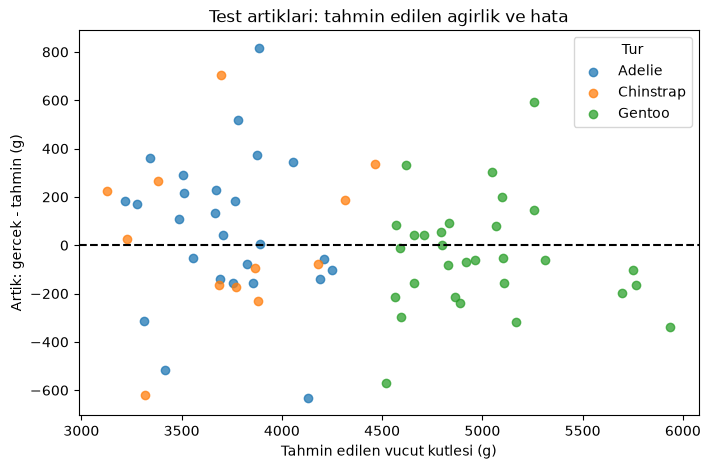

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for species, rows in comparison.groupby("species"):
    ax.scatter(
        rows["predicted_g"],
        rows["residual_g"],
        label=species,
        alpha=0.75,
    )

ax.axhline(0, color="black", linestyle="--")
ax.set_title("Test artiklari: tahmin edilen agirlik ve hata")
ax.set_xlabel("Tahmin edilen vucut kutlesi (g)")
ax.set_ylabel("Artik: gercek - tahmin (g)")
ax.legend(title="Tur")

plt.show()

## Tek özellikli doğrusal regresyonu elle öğrenmek

Soru: Yalnızca yüzgeç uzunluğunu kullanarak vücut kütlesini nasıl tahmin ederiz?
Eğitim satırlarında, tahmin ile gerçek ağırlık arasındaki kareli farkların
toplamını en küçük yapan doğrunun eğimini ve sabit terimini hesaplıyoruz.
Test satırları katsayıları öğrenmek için kullanılmıyor; yalnızca öğrenilmiş
doğrunun yeni satırlardaki hatasını ölçüyor.

In [6]:
from data import load_penguins, prepare_split

_, train, test = prepare_split(load_penguins())

x_train = train["flipper_length_mm"]
y_train = train["body_mass_g"]

x_centered = x_train - x_train.mean()
y_centered = y_train - y_train.mean()

slope = (x_centered * y_centered).sum() / x_centered.pow(2).sum()
intercept = y_train.mean() - slope * x_train.mean()

manual_prediction = intercept + slope * test["flipper_length_mm"]
error = test["body_mass_g"] - manual_prediction

print("Eğim (g/mm):", round(slope, 1))
print("Sabit terim (g):", round(intercept, 1))
print("Test MAE (g):", round(error.abs().mean(), 1))
print("Test RMSE (g):", round(error.pow(2).mean() ** 0.5, 1))

Eğim (g/mm): 49.9
Sabit terim (g): -5827.8
Test MAE (g): 274.6
Test RMSE (g): 359.0


### Gradient descent: hatayı adım adım azaltmak

Önce yüzgeç uzunluğunu eğitim ortalamasına göre merkezleyip standart
sapmasına bölüyoruz. Bu, güncelleme adımlarının sayısal olarak yönetilmesini
kolaylaştırır. Her adımda yalnızca eğitim kayıtlarının MSE değeri ve bu
hatanın parametrelere göre yönü hesaplanır; test kayıtları öğrenmeye katılmaz.

In [7]:
x_mean = x_train.mean()
x_scale = x_train.std(ddof=0)
z_train = (x_train - x_mean) / x_scale

a = 0.0
b = 0.0
learning_rate = 0.25

for step in range(1, 21):
    prediction = a + b * z_train
    residual = prediction - y_train

    gradient_a = 2 * residual.mean()
    gradient_b = 2 * (residual * z_train).mean()

    a -= learning_rate * gradient_a
    b -= learning_rate * gradient_b

    if step in (1, 2, 5, 10, 20):
        mse = ((a + b * z_train - y_train) ** 2).mean()
        print(step, "MSE:", round(mse, 1))

gd_slope = b / x_scale
gd_intercept = a - gd_slope * x_mean

print("Gradient descent eğimi (g/mm):", round(gd_slope, 1))
print("Gradient descent sabiti (g):", round(gd_intercept, 1))

1 MSE: 4649597.4
2 MSE: 1283116.2
5 MSE: 178489.5
10 MSE: 160972.9
20 MSE: 160955.8
Gradient descent eğimi (g/mm): 49.9
Gradient descent sabiti (g): -5827.8
